---
title: "Dynamics of a straight channel"
subtitle: "..."
description: "Dynamics of the water in a straight channel with closed end, subject to different level of the sea at the open end."
section: 2
author: "Basics"
date: "2026-11-25"
lang: en
date-modified: last-modified
categories: [shallow water equations, hyperbolic problems, wave equations, frequency response]
toc: true
toc-title: "On this page"
format:
  html:
    code-fold: true
number-sections: true
number-depth: 4
---



Description of:

* governing equations
* toy problem
* effects appearing in this model


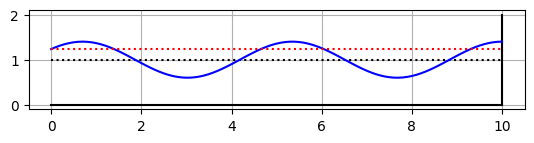

In [1]:
import numpy as np
import matplotlib.pyplot as plt

CHANNEL_L = 10.
CHANNEL_H = 1.
WAVE_AMPL = .4
n = 4.3

xFLOOR = np.array([ 0., CHANNEL_L ])
yFLOOR = np.array([ 0., 0. ])
xHEAD = np.array([ CHANNEL_L, CHANNEL_L ])
yHEAD = np.array([ 0., 2*CHANNEL_H ])
xWAVE = np.linspace(0, CHANNEL_L, 101)
yWAVE = CHANNEL_H + WAVE_AMPL * np.cos( n * (xWAVE-CHANNEL_L) / CHANNEL_L * np.pi )
xREF = np.array([ 0., CHANNEL_L ])
yREF = np.array([ CHANNEL_H, CHANNEL_H ])
yFREE = np.array([ 1, 1 ]) * yWAVE[0]

fig, ax = plt.subplots()
ax.plot(xFLOOR, yFLOOR, color="black")
ax.plot(xHEAD , yHEAD , color="black")
ax.plot(xREF  , yREF  , ":", color="black")
ax.plot(xWAVE , yWAVE , color="blue")
ax.plot(xFLOOR , yFREE , ":", color="red")
ax.set_aspect("equal")
ax.grid()
# fig.show()




## Governing equations
**Shallow water equations** are used here to model the dynamics of the water in the channel. **Link** 

::: {.callout-note collapse="true"}
### Shallow water equations

### Non-linear equations in a multi-dimensional domain

In conservative form

$$\left\{ \begin{aligned}
 & \partial_t \zeta + \nabla \cdot \left( \zeta \mathbf{u} \right) = 0 \\
 & \partial_t \left( \zeta \mathbf{u} \right) + \nabla \cdot \left( \zeta \mathbf{u} \otimes \mathbf{u} + \frac{g \zeta^2}{2} \mathbf{I} \right) = \mathbf{0} \ ,
\end{aligned}\right.$$

or in convective form

$$\left\{ \begin{aligned}
 & \partial_t \zeta + \nabla \cdot \left( \zeta \mathbf{u} \right) = 0 \\
 & \zeta \partial_t \mathbf{u} +  \zeta \mathbf{u} \cdot \nabla  \mathbf{u} + g \zeta \nabla \zeta = \mathbf{0} \ ,
\end{aligned}\right.$$

### Linearized equations in a 1-dimensional domain

The linearized equations around the reference state $(\zeta, u) = (h, 0)$ read

$$\left\{ \begin{aligned}
 & \partial_t \zeta + h \partial_x u = 0 \\
 & \partial_t u + g \partial_x \zeta = 0 \ .
\end{aligned}\right.$$

In this model a linear friction contribution ($r \ge 0$) is introduced to the momentum equation

$$\partial_t u + g \partial_x \zeta + r u = 0 \ ,$$

adding a reactive term to the convection modeled in the hyperbolic system.

### Wave equation, with dissipation

$$\begin{aligned}
  0
  & = \partial_{tt} \zeta + h \partial_{xt} u = \\
  & = \partial_{tt} \zeta - h \partial_x \left( g \partial_x \zeta + r u \right) =  \\
  & = \partial_{tt} \zeta - gh \partial_{xx} \zeta - h r \partial_x u = \\
  & = \partial_{tt} \zeta - gh \partial_{xx} \zeta + r \partial_t \zeta \ .
\end{aligned}$$

:::

## Toy problem


The problem can be recast as a modified wave equation with dissipation

$$\left\{ \begin{aligned}
  & \frac{1}{gh} \partial_{tt} \zeta - \partial_{xx} \zeta + \frac{r}{gh} \partial_t \zeta = 0 \\
  & \zeta(0,t) = Z f(t) \\
  & \partial_x \zeta(L,t) = 0
\end{aligned}\right.$$



:::{.callout-note collapse="true"}
### 
The equations in the domain are supplied with boundary conditions. Convective form of the non-linear equation in 1-dimensional domain w.r.t. an inertial reference frame,

$$\left\{ \begin{aligned}
 & \partial_t \zeta + \zeta \partial_x u + u \partial_x \zeta = 0 \\
 & \partial_t u + u \partial_x u + g \partial_x \zeta = 0 \ .
\end{aligned}\right.$$

**Linearized equations.** Around the reference condition $(\zeta_0, u_0) = (h, 0)$.

$$\left\{ \begin{aligned}
 & \partial_t \zeta + h \partial_x u = 0 \\
 & \partial_t u + g \partial_x \zeta = 0 \ .
\end{aligned}\right.$$

In the simulation a linear friction contribution ($r \ge 0$) is added to the momentum equation

$$\partial_t u + g \partial_x \zeta + r u = 0 \ ,$$

adding a reactive term to the convection modeled in the hyperbolic system.

**Boundary conditions.**

$$\begin{aligned}
  \zeta(0,t) & = Z f(t) \quad , \quad
  u(L,t) = 0
\end{aligned}$$

Since the second condition holds for all the time-steps then $\partial_t u(L,t) = 0$, and linearized momentum equation implies $\partial_x \zeta = - \frac{1}{g} \partial_t u$, then the second boundary conditions can be written as a function of $\zeta$,

$$\partial_x \zeta( L, t) = 0 \ .$$

A wave equation for $\zeta$ follows from the linearized hyperbolic system, so that the problem can be written as a function of $\zeta(x,t)$ only

$$\left\{ \begin{aligned}
  & \frac{1}{gh} \partial_{tt} \zeta - \partial_{xx} \zeta = 0 \\
  & \zeta(0,t) = Z f(t) \\
  & \partial_x \zeta(L,t) = 0
\end{aligned}\right.$$

**Modified wave equation for the system with friction.**

$$\begin{aligned}
  0
  & = \partial_{tt} \zeta + h \partial_{xt} u = \\
  & = \partial_{tt} \zeta - h \partial_x \left( g \partial_x \zeta + r u \right) =  \\
  & = \partial_{tt} \zeta - gh \partial_{xx} \zeta - h r \partial_x u = \\
  & = \partial_{tt} \zeta - gh \partial_{xx} \zeta + r \partial_t \zeta \ .
\end{aligned}$$

:::


:::{.callout-note collapse="true"}
### Analytical solution of the ideal system, with series on natural modes

**Analytical solution of the problem.** The solution can be written as the sum of a uniform function (fast part, as it instantaneously adapts to the boundary condition), and the series of natural modes (that can be then separated into slow modes - whose dynamics is solved - and fast modes - that are either truncated, or whose contribution is statically recovered),

$$\zeta(x,t) = \zeta_0(t) + \sum_{n=1}^{+\infty} f_n(x) g_n(t) = \zeta_0(t) + \widetilde{\zeta}(x,t) \ .$$

The uniform function identically satisfies the boundary condition in $x = L$. In order to satisfy the boundary condition in $x=0$ for $\forall t$, $\zeta_0(t) = Z f(t)$. This function doesn't satisfy the wave equation, and thus it acts as a forcing contribution for the series of natural modes,

$$\frac{1}{c^2} \partial_{tt} \widetilde\zeta - \partial_{xx} \widetilde\zeta = - \frac{1}{c^2} \partial_{tt} \zeta_0 = - \frac{Z}{c^2} \ddot{f}(t) \ .$$


**Natural modes** are evaluated solving the homogeneous problem for $\widetilde\zeta(x,t)$, using separation of variables,

$$- k_n^2 = \frac{f''_n(x)}{f_n(x)} \qquad \text{only if homogeneous} = \frac{1}{c^2} \frac{\ddot{g}_n(t)}{g_n(t)} $$

* applying boundary conditions to set constants of integration

   $$f_n(x) = A_n \sin\left( k_n x \right) \ ,$$

   with $k_n = \left( n - \frac{1}{2} \right) \frac{\pi}{L}$.
  
* then solving the inhomogeneous problem to evaluate the time coefficients of the natural modes, exploiting their orthogonality

$$\sum_{n=1}^{+\infty} \left\{ \frac{1}{c^2} \ddot{g}_n(t)  + k_n^2 g_n(t)  \right\} \sin(k_n x) = - \frac{Z}{c^2} \ddot{f}(t) \ ,$$


Multiplying by $\sin(k_m x)$ and integrating over $x \in [0, L]$ provides the decoupled dynamical equations for the amplitude of the modes,

$$\ddot{g}_{n}(t) + \omega_n^2 g_{n}(t) = - \frac{2}{\left(n-\frac{1}{2}\right) \pi} Z \ddot{f}(t) \ ,$$

with $\omega_n = c k_n$.

:::


:::{.callout-note collapse="true"}
### Details about Fourier expansion and orthogonality of Fourier base functions

$$\begin{aligned}
  \int_{x=0}^{L} \sin\left[ \left( n- \frac{1}{2} \right) \frac{\pi}{L} x \right] \sin\left[  \left( m - \frac{1}{2} \right) \frac{\pi}{L} x \right] \, dx
  & = \frac{1}{2} \int_{x=0}^{L} \left\{ \cos\left[ \left( n - m \right) \frac{\pi}{L} x \right] - \cos\left[  \left( n + m - 1 \right) \frac{\pi}{L} x \right] \right\} \, dx = \\
\end{aligned}$$

using

$$\cos(\alpha \mp \beta) = \cos \alpha \cos \beta \pm \sin \alpha \sin \beta$$

$$\sin \alpha \sin \beta = \frac{1}{2} \left[ \cos(\alpha - \beta) - \cos(\alpha + \beta) \right]$$

The factor $n-m$ is equal to zero if $m = n$, its cosine is equal to $1$, and the integral over $x \in [0,L]$ is equal to $\frac{L}{2}$. If $m \ne n$, then the integral is identically zero, since $\frac{L}{\pi(n-m)} \left. \sin\left( (n-m) \frac{\pi x}{L} \right)\right|_{x=0}^{L} = 0$.

Since $m,n \in \mathbb{N}^+$, the factor $n+m-1$ is always positive, and the integral of the second term is identically zero, since $\frac{L}{\pi(n+m-1)} \left. \sin\left( (n+m-1) \frac{\pi x}{L} \right)\right|_{x=0}^{L} = 0$.

---

$$\int_{x=0}^{L} \sin\left[  \left( m - \frac{1}{2} \right) \frac{\pi}{L} x \right] \, dx = - \frac{L}{\left( m - \frac{1}{2} \right) \pi} \left. \cos \left[ \left( m - \frac{1}{2} \right) \frac{\pi}{L} x \right]\right|_{x=0}^{L} = \frac{L}{\left( m - \frac{1}{2} \right) \pi} \ .$$


:::

:::{.callout-note collapse="true"}
### Analytical solution of the dissipative system, with series on natural modes

**Analytical solution** Sum of a uniform function and a series of natural modes. The uniform function $\zeta_0(x,t) = Z f(t)$ satisfies the non-homogeneous boundary conditions. Thus, the PDE for the series of natural modes is the non-homogeneous wave equation

$$\frac{1}{c^2} \partial_{tt} \widetilde\zeta - \partial_{xx} \widetilde\zeta + \frac{r}{c^2} \partial_t \widetilde\zeta = - \frac{Z}{c^2} \left( \ddot{f} + r \dot{f} \right) \ .$$

Natural modes are computed using separation of variables, $\widetilde\zeta(x,t) = \sum_{n=1}^{+\infty} f_n(x) g_n(t)$,

$$0 = \ddot{g} f - c^2 f'' g + r \dot{g} f \ ,$$

and dividing by $c^2 g f$, and separating on opposite sides of the equal sign the functions of $x$ and $t$

$$-k_n^2 = \frac{f_n''}{f_n}  \qquad \text{only if homogeneous} = \frac{1}{c^2}\frac{\ddot{g}_n + r \dot{g}_n}{g_n} \ .$$

and prescribing homogeneous boundary conditions for $\widetilde\zeta$, $\widetilde\zeta(0,t) = 0$, $\partial_x \zeta(L,t) = 0$ (this condition can be derived from the boundary condition on $u(L,t)$ and the momentum equation), it follows

$$f_n(x) = A_n \sin(k_n x) \ ,$$

with $k_n = \left( n - \frac{1}{2} \right) \frac{\pi}{L}$. Introducing the series of natural modes in the non-homogeneous wave equation

$$\sum_{n=1}^{+\infty} \left\{ \ddot{g}_{n} + r \dot{g}_{n} + \omega_n^2 g_{n} \right\} \sin(k_n x) = - Z \left( \ddot{f} + r \dot{f} \right) \ ,$$

with $\omega_n = k_n c = k_n \sqrt{gh}$. Exploiting the orthogonality of the basis functions, the  decoupled set of equations for the amplitude of the modes reads

$$\ddot{g}_n + r \dot{g}_n + \omega_n^2 g_n = - \frac{2 Z}{\left(n-\frac{1}{2}\right) \pi} \left( \ddot{f}(t) + r \dot{f}(t) \right) \ .$$



:::

:::{.callout-note collapse="true"}
### Height of the water at the head of the channel

The height of the free surface of the water at the head of the bay in $x = L$ is

$$\begin{aligned}
  \zeta(L,t)
  & = \zeta_0(t) + \sum_{n=1}^{+\infty} g_n(t) \sin\left( k_n L \right) = \\
  & = \zeta_0(t) + \sum_{n=1}^{+\infty} g_n(t) (-1)^{n+1} \ ,
\end{aligned}$$

since $\sin(k_n L) = (-1)^{n+1}$.

:::

## Frequency response

:::{.callout-note collapse="true"}
### Solution in Fourier domain of Helmholtz equation

**Solving in frequency response the modified wave equation.** The semi-Fourier transform of the function $\zeta(x,t)$,

$$\hat{\zeta}(x,\omega) := \mathscr{F}\{ \zeta(x,t) \}(\omega) = \frac{1}{\sqrt{2 \pi}} \int_{t=-\infty}^{+\infty} \zeta(x,t) e^{-i\omega t} \, dt \ ,$$

satisfies transformed modified homogeneous wave equation

$$0 = -\omega^2 \hat{\zeta} - c^2 \hat{\zeta}'' + i \omega r \hat{\zeta}  \quad \rightarrow \quad  \hat{\zeta}'' + \frac{\omega^2 - i \omega r}{c^2} \hat{\zeta} = 0 \ ,$$

being $( \cdot )' = \partial_x \left( \cdot \right)|_\omega$, with boundary conditions

$$
  \hat{\zeta}(0, \omega) = Z \hat{f}(\omega) \qquad , \qquad
  \hat{\zeta}'(L, \omega) = 0 \ .
$$

The solution of the equation in frequency domain reads $\hat{\zeta}(x,\omega) = A_1 e^{i k_1 x} + A_2 e^{i k_2 x}$, with $k_{1,2}$ the solutions of the equation

$$k^2 = \frac{\omega^2 - i \omega r}{c^2} \ ,$$

with $k_{1,2}(\omega) = |k(\omega)| e^{i \left( \phi(\omega) + \pi (n-1) \right)}$, with

$$|k(\omega)| = \dots \quad , \quad \phi(\omega) = \dots$$

The two solutions are opposite, $k_2 = - k_1$, and thus the solution in the frequency domain reads

$$\hat{\zeta}(x,\omega) = A_1 e^{i k_1 x} + A_2 e^{-i k_1 x} \ .$$

**Prescribing the boundary conditions.**

$$\begin{aligned}
  Z \hat{f}(\omega) & = \hat{\zeta}(0,\omega) = A_1 + A_2 \\
  0 & = \hat{\zeta}'(L,\omega) = i k_1 \left( A_1 e^{i k_1 L} - A_2 e^{-i k_1 L} \right) \ ,
\end{aligned}$$

and thus $A_2 = A_1 e^{i 2 k_1 L}$, and

$$Z \hat{f}(\omega) = A_1 \left( 1 + e^{i 2 k_1 L} \right)$$

$$\quad \rightarrow \quad
\left\{ \begin{aligned}
  A_1 & = \frac{Z \hat{f}(\omega)}{1 + e^{i 2 k_1 L}} \\
  A_2 & = \frac{Z \hat{f}(\omega)}{1 + e^{-i 2 k_1 L}}
\end{aligned}\right.$$


 so that

$$\begin{aligned}
  \hat{\zeta}(x,\omega)
  & = A_1 e^{i k_1 x} + A_2 e^{-i k_1 x} = \\
  & = Z \hat{f}(\omega) \left\{ e^{-i k_1 L} \frac{e^{i k_1 x}}{e^{-i k_1 L} + e^{i k_1 L}} + e^{i k_1 L} \frac{e^{-i k_1 x}}{e^{-i k_1 L} + e^{i k_1 L}} \right\} \\
  & = Z \hat{f}(\omega) \left\{ \frac{ e^{i k_1 (x-L)} +  e^{-i k_1 (x-L)} }{e^{-i k_1 L} + e^{i k_1 L}} \right\} = \\
  & = Z \hat{f}(\omega) \frac{\cos(k_1(L-x))}{\cos(k_1 L)} \\
\end{aligned}$$

In general $k_1$ is complex, $k_1 = k_r + i k_i$, so that

$$\begin{aligned}
  \cos(k_1 x)
  & = \frac{ e^{i k_r x} e^{-k_i x} + e^{-i k_r x} e^{k_i x}}{2} = \\
  & = \frac{[ \cos(k_r x) + i \sin(k_r x) ] e^{-k_i x} + [ \cos(k_r x) - i \sin(k_r x) ] e^{k_i x}}{2} = \\
  & = \cos(k_r x) \cosh(k_i x) - i \sin(k_r x) \sinh(k_i x) \ .
\end{aligned}$$

having exploited Euler relation and the definition of hyperbolic functions,

$$\begin{aligned}
  e^{i x} & = \cos(x) + i \sin(x) \\
  \cosh x & = \frac{e^x + e^{-x}}{2} \\
  \sinh x & = \frac{e^x - e^{-x}}{2}
\end{aligned}$$

:::

:::{.callout-note collapse="true"}

**Height at the head of the channel.** The height at the head of the channel is $\zeta(L,t)$. The frequency response follows

$$\hat{\zeta}(L, \omega) = Z \hat{f}(\omega) \frac{1}{\cos(k_1 L)} \ ,$$

with the **transfer function**

$$G(L, \omega) = \frac{1}{\cos(k_1 L)} = \frac{1}{\cos(k_r L) \cosh(k_i L) - i \sin(k_r L) \sinh(k_i L)}$$
:::

:::{.callout-note collapse="true"}
### Transfer function of the mode amplitude $\ G_n(\omega)$


Let $f(t) = e^{i \omega t}$ the frequency response of the amplitude of the $n^{\rm th}$ mode has (complex) amplitude

$$G_n(\omega) = - \frac{2 Z}{\left(n-\frac{1}{2}\right) \pi} \cdot \frac{-\omega^2 + i r \omega}{-\omega^2 + i r \omega + \omega_n^2}$$

:::

In [2]:
"""
Unsteady tides and resonance  (Colab / Plotly)
==============================================
LEVEL 1  Quarter-wave bay (Bay-of-Fundy-like): analytic resonance curve, checked
         against a time-domain finite-difference solver.
"""

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

pio.renderers.default = "notebook_connected"

# ───────────────────────── constants (SI) ─────────────────────────
G     = 6.67430e-11
M_E   = 5.9722e24
M_m   = 7.342e22
a     = 6.371e6                      # Earth radius
R_EM  = 3.844e8
Omega = 7.2921159e-5                 # sidereal spin rate
w_orb = 2*np.pi/(27.321661*86400.0)  # orbital rate (sidereal month)
g     = G*M_E/a**2

# ───────────────────────── user parameters ─────────────────────────
# Level 1: bay open at x=0 (sea tide imposed), closed at x=L
BAY_L, BAY_H, BAY_R = 300e3, 70.0, 5e-5      # length [m], depth [m], linear friction [1/s]
EPS_DEG        = 23.44        # obliquity (spin axis vs orbit normal)
THETA10_DEG    = 0.0          # initial orbital phase of the Earth centre

eps, theta10 = np.radians(EPS_DEG), np.radians(THETA10_DEG)
A = 1.5*(M_m/M_E)*a**4/R_EM**3                  # tidal amplitude coefficient [m]

# ==============================================================================
# Useful functions
# ==============================================================================
#   zeta_t + h u_x = 0 ,  u_t = -g zeta_x - r u ,  zeta(0,t) = Z cos(w t),  u(L,t)=0
# Frequency domain (exp(-i w t)):  zeta(x) = Z cos(k(L-x))/cos(kL),  k^2 = w(w + i r)/(g h)
# Gain at the head = 1/|cos(kL)|  ->  resonance at kL = pi/2, i.e. T0 = 4L/sqrt(gh).
def k_complex(sigma, h, r):
    return np.sqrt(sigma*(sigma + 1j*r)/(g*h) + 0j)


def bay_gain_head(T_h, L, h, r):
    sigma = 2*np.pi/(np.asarray(T_h)*3600.0)
    return 1.0/np.abs(np.cos(k_complex(sigma, h, r)*L))


def bay_profile(x, T_h, L, h, r):
    k = k_complex(2*np.pi/(T_h*3600.0), h, r)
    return np.abs(np.cos(k*(L - x))/np.cos(k*L))


def simulate_bay(T_h, L, h, r, Zs=1.0, N=150, cfl=0.5):
    """Forward-backward staggered-grid solver; returns the gain at the head."""
    c = np.sqrt(g*h); dx = L/N; dt = cfl*dx/c
    T = T_h*3600.0; w = 2*np.pi/T
    t_end = 6*(2.0/r) + 8*T
    n = int(t_end/dt)
    zeta = np.zeros(N); u = np.zeros(N + 1)
    gdt, hdt, fr = g*dt/dx, h*dt/dx, 1.0/(1.0 + r*dt)
    head = np.empty(n)
    for s in range(n):
        t = (s + 1)*dt
        zeta -= hdt*(u[1:] - u[:-1])
        u[1:N] = (u[1:N] - gdt*(zeta[1:] - zeta[:-1]))*fr
        u[0] = (u[0] - 2*gdt*(zeta[0] - Zs*np.cos(w*t)))*fr      # sea level imposed at x = 0
        head[s] = zeta[-1]
    times = dt*np.arange(1, n + 1)
    m = times >= t_end - 4*T
    Mx = np.column_stack([np.cos(w*times[m]), np.sin(w*times[m]), np.ones(m.sum())])
    coef = np.linalg.lstsq(Mx, head[m], rcond=None)[0]
    return np.hypot(coef[0], coef[1])/Zs


In [3]:
# ==============================================================================
# Simulation
# ==============================================================================

c_bay = np.sqrt(g*BAY_H)
T0_h = 4*BAY_L/c_bay/3600.0

print("== LEVEL 1: bay L=%.0f km, h=%.0f m, r=%.1e 1/s ==" % (BAY_L/1e3, BAY_H, BAY_R))
print("natural (quarter-wave) period T0 = 4L/sqrt(gh) = %.2f h   (M2 = 12.42 h, K1 = 23.93 h)" % T0_h)

T_sim = sorted({5.0, 8.0, 12.42, round(T0_h, 2), 18.0, 23.93, 36.0})
gain_an = bay_gain_head(T_sim, BAY_L, BAY_H, BAY_R)
gain_sim = np.array([simulate_bay(T, BAY_L, BAY_H, BAY_R) for T in T_sim])

for T, ga, gs in zip(T_sim, gain_an, gain_sim):
    print("  T = %5.2f h   gain analytic %.3f   time-domain %.3f   (diff %.2f%%)" % (T, ga, gs, 100*(gs/ga - 1)))

assert np.all(np.abs(gain_sim/gain_an - 1) < 0.03), "level-1 time-domain solver disagrees with analytic gain"


== LEVEL 1: bay L=300 km, h=70 m, r=5.0e-05 1/s ==
natural (quarter-wave) period T0 = 4L/sqrt(gh) = 12.71 h   (M2 = 12.42 h, K1 = 23.93 h)
  T =  5.00 h   gain analytic 1.405   time-domain 1.408   (diff 0.20%)
  T =  8.00 h   gain analytic 1.165   time-domain 1.164   (diff -0.07%)
  T = 12.42 h   gain analytic 3.424   time-domain 3.423   (diff -0.01%)
  T = 12.71 h   gain analytic 3.491   time-domain 3.492   (diff 0.02%)
  T = 18.00 h   gain analytic 1.997   time-domain 1.999   (diff 0.09%)
  T = 23.93 h   gain analytic 1.437   time-domain 1.438   (diff 0.04%)
  T = 36.00 h   gain analytic 1.164   time-domain 1.164   (diff 0.02%)


In [4]:
# ==============================================================================
# Figures
# ==============================================================================

T_grid = np.geomspace(3, 48, 400)


In [5]:
# ------------------------------------------------------------------------------
# Frequency response of the natural modes
# ------------------------------------------------------------------------------
c = np.sqrt(g*BAY_H)

Gn_fun = lambda omega, n, omega_n, r: 2./np.pi/(n-.5) * (omega**2 - 1j*r*omega) / (omega_n**2 - omega**2 + 1j*r*omega)
omega_grid = 2. * np.pi / ( T_grid * 3600 )

fig2 = make_subplots(rows=2, cols=1)

Gn_grid = []
n_modes = 5

for n in np.arange(1, n_modes+1):

    k_n = (n - 0.5) * np.pi / BAY_L
    omega_n = k_n * c
    Gn_grid += [ Gn_fun(omega_grid, n, omega_n, BAY_R) ]

    # print(n, omega_n * 3600 / (2*np.pi))

for n in np.arange(0, n_modes):

    fig2.add_trace(go.Scatter(x=T_grid, y=np.abs(Gn_grid[n]), mode="lines",
                          name=f"n={n+1}", line=dict(width=3)), row=1, col=1)

for n in np.arange(0, n_modes):

    fig2.add_trace(go.Scatter(x=T_grid, y=np.unwrap(np.angle(Gn_grid[n])), mode="lines",
                          name=f"n={n+1}", line=dict(width=3), showlegend=False), row=2, col=1)


fig2.update_layout(height=900, width=600, template="plotly_white",
                   title="Frequency response of natural modes")
fig2.update_xaxes(title_text="forcing period, $T$ [h]", type="log", row=1, col=1)
fig2.update_yaxes(title_text=r"gain, $|G_n|(T)$", row=1, col=1)
fig2.update_xaxes(title_text="forcing period, $T$ [h]", type="log", row=2, col=1)
fig2.update_yaxes(title_text=r"phase, $\angle G_n(T)$", row=2, col=1)
fig2.show()


In [6]:
# ------------------------------------------------------------------------------
# Frequency response of the exact solution, evaluated at the Head of the channel
# ------------------------------------------------------------------------------

G_head_grid = Gn_grid[0] + 1.
for n in np.arange(1, n_modes):
    G_head_grid += (Gn_grid[n]*(-1)**n)

fig1 = make_subplots(rows=1, cols=2, horizontal_spacing=0.1,
                     subplot_titles=("Gain at the head of the bay (amplitude / open-sea amplitude)",
                                     r"$\text{Spatial structure } \frac{|\zeta(x)|}{Z}$"))

fig1.add_trace(go.Scatter(x=T_grid, y=bay_gain_head(T_grid, BAY_L, BAY_H, BAY_R), mode="lines",
                          name="analytic", line=dict(width=3)), row=1, col=1)

fig1.add_trace(go.Scatter(x=T_grid, y=np.abs(G_head_grid), mode="lines",
                          name=f"modal n_modes: {n_modes}", line=dict(width=3, dash="dot", color="black")), row=1, col=1)

fig1.add_trace(go.Scatter(x=T_sim, y=gain_sim, mode="markers", name="time-domain simulation",
                          marker=dict(size=10, symbol="diamond", color="crimson")), row=1, col=1)

for lab, Tv, col in (("M2 12.42 h", 12.42, "green"), ("K1 23.93 h", 23.93, "purple"),
                     ("natural period T0 = %.1f h" % T0_h, T0_h, "orange"), ("6 h", 6.0, "darkcyan"),
                     ("4.25 h", 4.25, "magenta")):
    fig1.add_vline(x=Tv, line=dict(color=col, dash="dot"), row=1, col=1)
    fig1.add_annotation(x=np.log10(Tv), y=1.0, yref="y domain", xref="x", text=lab, textangle=-90,
                        showarrow=False, xanchor="right", yanchor="top", font=dict(color=col, size=11))
xk = np.linspace(0, BAY_L, 300)

for lab, Tv, color in (("M2", 12.42, "green"), ("K1", 23.93, "purple"), ("T0", T0_h, "orange"),
                       ("6 h", 6.0, "darkcyan"), ("4.25 h", 4.25, "magenta")):
    fig1.add_trace(go.Scatter(x=xk/1e3, y=bay_profile(xk, Tv, BAY_L, BAY_H, BAY_R), mode="lines", line=dict(color=color),
                              name="T = %s" % lab), row=1, col=2)
fig1.update_xaxes(title_text="forcing period [h]", type="log", row=1, col=1)
fig1.update_yaxes(title_text="gain", row=1, col=1)
fig1.update_xaxes(title_text="distance from the mouth [km]", row=1, col=2)
fig1.update_yaxes(title_text="amplitude ratio", row=1, col=2)
fig1.update_layout(height=480, width=1200, template="plotly_white",
                   title="Level 1: resonance of a quarter-wave bay (L = %.0f km, h = %.0f m, r = %.0e 1/s)"
                         % (BAY_L/1e3, BAY_H, BAY_R))
fig1.show()
